# Hafta 11 — GPT-2'yi hızlı eğitilebilir hâle getirmek

Geçen hafta GPT-2'yi (124M) yazdık, OpenAI'ın ağırlıklarını içine yükledik ve tek bir batch'i ezberlettik. Bu hafta aynı modeli gerçekten eğitilebilir hâle getiriyoruz.

**Akış:** Önce metnin tamamını gezen bir data loader, weight tying ve doğru başlangıç değerleri. Sonra bir eğitim adımını ölçüp GPU'daki hızlandırmaları tek tek ekliyoruz. En son GPT-3 makalesinin eğitim ayarlarını kurup hepsini birlikte birkaç yüz adım çalıştırıyoruz.

**Donanım:** Bu notebook Kaggle'da **Tesla T4 (14,6 GB)** üstünde koştu, Colab'ın ücretsiz GPU'suyla aynı kart. Aşağıdaki bütün süreler bu karttan.

| Görev | Konu | Video |
|---|---|---|
| 1 | Data loader, weight tying ve başlangıç değerleri | 1:02:00 – 1:22:18 |
| 2 | Eğitimi hızlandırmak: float16, torch.compile, flash attention, vocab 50.304 | 1:22:18 – 2:14:55 |
| 3 | GPT-3'ün eğitim ayarları: AdamW, gradient clipping, lr schedule, weight decay, gradient accumulation | 2:14:55 – 2:46:52 |

**Kaynaklar:** [Karpathy, "Let's reproduce GPT-2 (124M)"](https://www.youtube.com/watch?v=l8pRSuU81PU) · [build-nanogpt](https://github.com/karpathy/build-nanogpt) · [GPT-3 makalesi, ek B](https://arxiv.org/abs/2005.14165)

In [1]:
# Colab'da yoksa: !pip install tiktoken
import math, time, os, gc, inspect, urllib.request
from dataclasses import dataclass
import torch
import torch.nn as nn
from torch.nn import functional as F
import tiktoken
import matplotlib.pyplot as plt

# attempt to autodetect the device
device = "cpu"
if torch.cuda.is_available():
    device = "cuda"
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    device = "mps" # Mac
print(f"using device: {device}")
print("torch:", torch.__version__)
if device == "cuda":
    print("GPU:", torch.cuda.get_device_name(0), f"{torch.cuda.get_device_properties(0).total_memory / 1024**3:.1f} GB")

using device: cuda
torch: 2.11.0+cu128
GPU: Tesla T4 14.6 GB


# **1- Data loader, weight tying ve başlangıç değerleri. Metni batch'lere bölen küçük bir data loader yaz ve metnin tamamında eğit. Weight tying'i ekle, kaç parametre kazandırdığını hesapla. Başlangıç değerlerini videodaki gibi ayarla: std 0.02, residual katmanlarda 1/√(2·n_layer) ile ölçekleme. Neden ölçeklediğimizi kendi cümlelerinle yaz. Geçen hafta ek görevde yaptıysan kısaca göstermen yeterli. (1:02:00 - 1:22:18)**

Model geçen haftakinin aynısı. Üç yer değişti:

- `GPT.__init__`'te **weight tying:** `wte` ile `lm_head` artık aynı tensor.
- `_init_weights`: başlangıç değerlerini kendimiz veriyoruz, std 0.02.
- `NANOGPT_SCALE_INIT`: residual yola yazan iki katmanı (`attn.c_proj` ve `mlp.c_proj`) işaretliyor, onların std'si ayrıca küçülüyor.

`flash` alanını Görev 2'de hızı ölçerken açıp kapatmak için ekledim. Hugging Face'ten ağırlık yüklemeyi çıkardım, bu hafta modeli sıfırdan eğitiyoruz.

In [2]:
class CausalSelfAttention(nn.Module):

    def __init__(self, config):
        super().__init__()
        assert config.n_embd % config.n_head == 0
        # key, query, value projections for all heads, but in a batch
        self.c_attn = nn.Linear(config.n_embd, 3 * config.n_embd)
        # output projection
        self.c_proj = nn.Linear(config.n_embd, config.n_embd)
        self.c_proj.NANOGPT_SCALE_INIT = 1 # bu katman residual yola yazıyor, başlangıç değeri ölçeklenecek
        # regularization
        self.n_head = config.n_head
        self.n_embd = config.n_embd
        self.flash = config.flash # görev 2'de açacağız
        # not really a 'bias', more of a mask, but following the OpenAI/HF naming though
        self.register_buffer("bias", torch.tril(torch.ones(config.block_size, config.block_size))
                                     .view(1, 1, config.block_size, config.block_size))

    def forward(self, x):
        B, T, C = x.size() # batch size, sequence length, embedding dimensionality (n_embd)
        # calculate query, key, values for all heads in batch and move head forward to be the batch dim
        # nh is "number of heads", hs is "head size", and C (number of channels) = nh * hs
        # e.g. in GPT-2 (124M), n_head=12, hs=64, so nh*hs=C=768 channels in the Transformer
        qkv = self.c_attn(x)
        q, k, v = qkv.split(self.n_embd, dim=2)
        k = k.view(B, T, self.n_head, C // self.n_head).transpose(1, 2) # (B, nh, T, hs)
        q = q.view(B, T, self.n_head, C // self.n_head).transpose(1, 2) # (B, nh, T, hs)
        v = v.view(B, T, self.n_head, C // self.n_head).transpose(1, 2) # (B, nh, T, hs)
        if self.flash:
            y = F.scaled_dot_product_attention(q, k, v, is_causal=True) # flash attention. alttaki 4 satırın aynı hesabı, tek çağrıda
        else:
            # attention (materializes the large (T,T) matrix for all the queries and keys)
            att = (q @ k.transpose(-2, -1)) * (1.0 / math.sqrt(k.size(-1)))
            att = att.masked_fill(self.bias[:,:,:T,:T] == 0, float('-inf'))
            att = F.softmax(att, dim=-1)
            y = att @ v # (B, nh, T, T) x (B, nh, T, hs) -> (B, nh, T, hs)
        y = y.transpose(1, 2).contiguous().view(B, T, C) # re-assemble all head outputs side by side
        # output projection
        y = self.c_proj(y)
        return y

class MLP(nn.Module):

    def __init__(self, config):
        super().__init__()
        self.c_fc    = nn.Linear(config.n_embd, 4 * config.n_embd)
        self.gelu    = nn.GELU(approximate='tanh')
        self.c_proj  = nn.Linear(4 * config.n_embd, config.n_embd)
        self.c_proj.NANOGPT_SCALE_INIT = 1 # bu da residual yola yazıyor

    def forward(self, x):
        x = self.c_fc(x)
        x = self.gelu(x)
        x = self.c_proj(x)
        return x

class Block(nn.Module):

    def __init__(self, config):
        super().__init__()
        self.ln_1 = nn.LayerNorm(config.n_embd)
        self.attn = CausalSelfAttention(config)
        self.ln_2 = nn.LayerNorm(config.n_embd)
        self.mlp = MLP(config)

    def forward(self, x):
        x = x + self.attn(self.ln_1(x))
        x = x + self.mlp(self.ln_2(x))
        return x

@dataclass
class GPTConfig:
    block_size: int = 1024 # max sequence length
    vocab_size: int = 50257 # number of tokens: 50,000 BPE merges + 256 bytes tokens + 1 <|endoftext|> token
    n_layer: int = 12 # number of layers
    n_head: int = 12 # number of heads
    n_embd: int = 768 # embedding dimension
    flash: bool = False # görev 2'de hızı ölçerken açıp kapatacağız

class GPT(nn.Module):

    def __init__(self, config):
        super().__init__()
        self.config = config

        self.transformer = nn.ModuleDict(dict(
            wte = nn.Embedding(config.vocab_size, config.n_embd),
            wpe = nn.Embedding(config.block_size, config.n_embd),
            h = nn.ModuleList([Block(config) for _ in range(config.n_layer)]),
            ln_f = nn.LayerNorm(config.n_embd),
        ))
        self.lm_head = nn.Linear(config.n_embd, config.vocab_size, bias=False)

        # weight sharing scheme
        self.transformer.wte.weight = self.lm_head.weight # iki katman artık aynı tensoru tutuyor. wte'nin kendi matrisi çöpe gidiyor

        # init params
        self.apply(self._init_weights) # bütün alt modülleri gezip _init_weights'i çağırıyor

    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            std = 0.02
            if hasattr(module, 'NANOGPT_SCALE_INIT'):
                std *= (2 * self.config.n_layer) ** -0.5 # 2 çünkü her blokta iki residual toplama var: attention ve MLP
            torch.nn.init.normal_(module.weight, mean=0.0, std=std)
            if module.bias is not None:
                torch.nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            torch.nn.init.normal_(module.weight, mean=0.0, std=0.02)
        # LayerNorm'a dokunmuyoruz, PyTorch'un varsayılanı zaten weight=1, bias=0

    def forward(self, idx, targets=None):
        # idx is of shape (B, T)
        B, T = idx.size()
        assert T <= self.config.block_size, f"Cannot forward sequence of length {T}, block size is only {self.config.block_size}"
        # forward the token and posisition embeddings
        pos = torch.arange(0, T, dtype=torch.long, device=idx.device) # shape (T)
        pos_emb = self.transformer.wpe(pos) # position embeddings of shape (T, n_embd)
        tok_emb = self.transformer.wte(idx) # token embeddings of shape (B, T, n_embd)
        x = tok_emb + pos_emb
        # forward the blocks of the transformer
        for block in self.transformer.h:
            x = block(x)
        # forward the final layernorm and the classifier
        x = self.transformer.ln_f(x)
        logits = self.lm_head(x) # (B, T, vocab_size)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1))
        return logits, loss

Geçen hafta tek bir batch'i tekrar tekrar veriyorduk. `DataLoaderLite` metni baştan sona ardışık parçalar halinde geziyor. Her `next_batch` çağrısında `B * T + 1` token alıyor, `x` ve `y`'yi hafta 10'daki gibi bir kaydırarak çıkarıyor ve konumu `B * T` ilerletiyor. Metnin sonuna gelince başa dönüyor.

In [3]:
if not os.path.exists("input.txt"): # tiny shakespeare
    urllib.request.urlretrieve("https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt", "input.txt")

enc = tiktoken.get_encoding("gpt2")

class DataLoaderLite:
    def __init__(self, B, T):
        self.B = B
        self.T = T

        # at init load tokens from disk and store them in memory
        with open("input.txt", "r", encoding="utf-8") as f:
            text = f.read()
        tokens = enc.encode(text)
        self.tokens = torch.tensor(tokens) # CPU'da tutuyoruz, GPU'ya yalnızca o anki batch gidiyor
        print(f"loaded {len(self.tokens)} tokens")
        print(f"1 epoch = {len(self.tokens) // (B * T)} batches")

        # state
        self.current_position = 0

    def next_batch(self):
        B, T = self.B, self.T
        buf = self.tokens[self.current_position : self.current_position + B * T + 1] # bir fazla token, son konumun da hedefi lazım
        x = (buf[:-1]).view(B, T) # inputs
        y = (buf[1:]).view(B, T) # targets
        # advance the position in the tensor
        self.current_position += B * T
        # if loading the next batch would be out of bounds, reset
        if self.current_position + (B * T + 1) > len(self.tokens):
            self.current_position = 0
        return x, y

In [4]:
train_loader = DataLoaderLite(B=4, T=32)

# ilk iki batch ardışık mı, y gerçekten x'in bir sağa kaymışı mı
x1, y1 = train_loader.next_batch()
x2, y2 = train_loader.next_batch()
assert torch.equal(x1.view(-1)[1:], y1.view(-1)[:-1]) # y, x'in bir kaymışı
assert x2[0, 0] == y1[-1, -1] # ikinci batch birincinin bittiği yerden başlıyor
print(repr(enc.decode(x1[0].tolist())))

# bir epoch'ta metnin başına dönüyor mu
n_batch = len(train_loader.tokens) // (4 * 32)
for _ in range(n_batch - 2):
    train_loader.next_batch()
print("bir epoch sonra konum:", train_loader.current_position)

loaded 338025 tokens
1 epoch = 2640 batches
'First Citizen:\nBefore we proceed any further, hear me speak.\n\nAll:\nSpeak, speak.\n\nFirst Citizen:\nYou are'
bir epoch sonra konum: 0


338.025 token, `B * T` = 128 token'lık batch'le 2.640 batch ediyor. Assert'ler geçti: `y`, `x`'in bir sağa kaymışı ve ikinci batch birincinin bittiği yerden başlıyor. 2.640 batch sonra konum 0'a döndü, yani bir epoch'ta metnin tamamını görüp başa dönüyor.

In [5]:
torch.manual_seed(1337)
model = GPT(GPTConfig())

# weight tying'siz halini de kuralım: lm_head'e kendi kopyasını veriyoruz
ayri = GPT(GPTConfig())
ayri.lm_head.weight = nn.Parameter(ayri.lm_head.weight.clone())

n_bagli = sum(p.numel() for p in model.parameters()) # parameters() paylaşılan tensoru bir kere sayıyor
n_ayri = sum(p.numel() for p in ayri.parameters())
print("wte ile lm_head aynı tensor mü:", model.transformer.wte.weight is model.lm_head.weight)
print(f"weight tying olmadan: {n_ayri:,}")
print(f"weight tying ile:     {n_bagli:,}")
print(f"kazanç:               {n_ayri - n_bagli:,} parametre, %{100 * (n_ayri - n_bagli) / n_ayri:.1f}")
print(f"bellekte:             {(n_ayri - n_bagli) * 4 / 1024**2:.0f} MB (float32, parametre başına 4 byte)")
del ayri

wte ile lm_head aynı tensor mü: True
weight tying olmadan: 163,037,184
weight tying ile:     124,439,808
kazanç:               38,597,376 parametre, %23.7
bellekte:             147 MB (float32, parametre başına 4 byte)


### Weight tying kaç parametre kazandırdı

**38.597.376 parametre** (50.257 × 768), yani modelin **%23,7**'si. 163.037.184'ten 124.439.808'e indik, float32'de 147 MB. Geçen hafta bizim modelin 163M, Hugging Face'inkinin 124M çıkmasının sebebi tam olarak buydu.

Ağırlık paylaşmak mantıklı çünkü `wte` ve `lm_head` aynı bilginin iki yönü. `wte` "bu token'ın anlamı ne" sorusunu cevaplıyor, `lm_head` "bu vektör hangi token'a benziyor" sorusunu. Anlamca yakın iki token'ın girişte yakın vektörleri olmasını, çıkışta da benzer olasılıklar almasını istiyoruz. "Attention Is All You Need" makalesi de aynı şeyi yapıyor (Bölüm 3.4).

`self.transformer.wte.weight = self.lm_head.weight` satırı `wte`'nin kendi matrisini kullanılmaz hale getiriyor. Hatırlatma: `parameters()` paylaşılan tensoru bir kere sayıyor, o yüzden 124M görüyoruz.

In [6]:
# Karpathy'nin küçük örneği: residual yol her blokta üstüne rastgele bir şey ekliyor
n = 100 # e.g. 100 layers
for ad, carpan in [("ölçeksiz", 1.0), ("n^-0.5 ile ölçekli", n ** -0.5)]:
    x = torch.zeros(768)
    for i in range(n):
        x += carpan * torch.randn(768)
    print(f"{ad:20} son std: {x.std().item():.3f}")

ölçeksiz             son std: 10.223
n^-0.5 ile ölçekli   son std: 1.000


### Neden ölçekliyoruz

Residual yolda `x = x + ...` satırı `x`'in üstüne sürekli yeni bir şey ekliyor. Başlangıçta eklenenler rastgele. Bağımsız rastgele sayıları topladıkça varyanslar toplanıyor, yani std toplama sayısının karekökü kadar büyüyor. Yukarıdaki küçük örnekte 100 toplamadan sonra std **10,22** oldu. Her toplamayı `n^-0.5` ile küçültünce **1,00**'da kaldı.

Şimdi aynısını gerçek modelde ölçelim. Bir blokta iki toplama var (attention ve MLP), 12 blokta 24 toplama. Formüldeki `2 * n_layer` buradan geliyor.

 blok   ölçekli  ölçeksiz
    0     0.028     0.028
    1     0.082     0.389
    2     0.115     0.592
    4     0.169     0.866
    8     0.245     1.247
   12     0.307     1.527


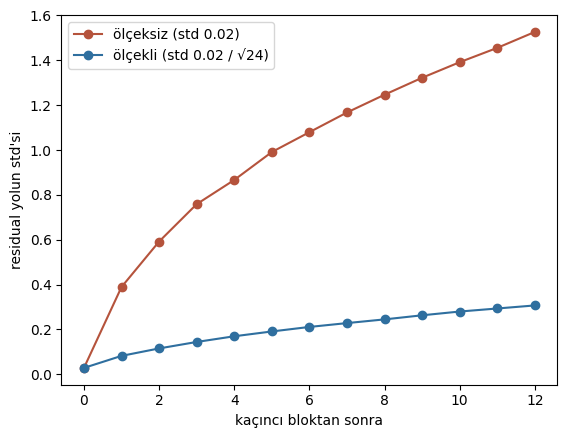

In [7]:
def residual_std(model, idx):
    # girdiyi bloklardan geçirip her bloktan sonra residual yolun std'sini ölçüyoruz
    T = idx.size(1)
    pos = torch.arange(T, device=idx.device)
    x = model.transformer.wte(idx) + model.transformer.wpe(pos)
    stdler = [x.std().item()]
    for block in model.transformer.h:
        x = block(x)
        stdler.append(x.std().item())
    return stdler

model.to(device)
idx = train_loader.tokens[:4 * 32].view(4, 32).to(device)
with torch.no_grad():
    olcekli = residual_std(model, idx)

# aynı model, ölçekleme olmadan: residual katmanları düz 0.02 ile yeniden başlatıyoruz
torch.manual_seed(1337)
olceksiz_model = GPT(GPTConfig()).to(device)
for m in olceksiz_model.modules():
    if hasattr(m, "NANOGPT_SCALE_INIT"):
        torch.nn.init.normal_(m.weight, mean=0.0, std=0.02)
with torch.no_grad():
    olceksiz = residual_std(olceksiz_model, idx)

print(f"{'blok':>5}{'ölçekli':>10}{'ölçeksiz':>10}")
for i in [0, 1, 2, 4, 8, 12]:
    print(f"{i:>5}{olcekli[i]:>10.3f}{olceksiz[i]:>10.3f}")

plt.plot(olceksiz, marker="o", color="#b5533c", label="ölçeksiz (std 0.02)")
plt.plot(olcekli, marker="o", color="#2f6f9f", label="ölçekli (std 0.02 / √24)")
plt.xlabel("kaçıncı bloktan sonra"); plt.ylabel("residual yolun std'si"); plt.legend()

### Gerçek modelde residual yol

| Bloktan sonra | Ölçekli | Ölçeksiz |
|---|---|---|
| 0 | 0,028 | 0,028 |
| 4 | 0,169 | 0,866 |
| 8 | 0,245 | 1,247 |
| 12 | 0,307 | 1,527 |

- 12. blokta ölçeksiz std ölçeklinin **4,97 katı**. √24 = 4,90, yani karekök kuralı gerçek modelde de tutuyor.
- Ölçeksiz modelde tek bir toplamanın katkısı yaklaşık 1,53 / √24 = 0,31. Ölçekleyince 0,31 / √24 = 0,06'ya iniyor.
- Dikkat: mavi çizgi de yükseliyor, ölçekleme büyümeyi durdurmuyor. Yaptığı şey **son değeri blok sayısından bağımsız** hale getirmek. 2·n_layer tane toplamanın her biri 1/√(2·n_layer) ile küçülünce toplam std n_layer'a bağlı olmuyor. 12 blok da 48 blok da yaklaşık aynı büyüklükte başlıyor.

**Kendi cümlelerimle:** Residual yolda her blok sonucun üstüne bir şey ekliyor. Ölçeklemezsek model derinleştikçe bu toplam da büyür ve modeli derinleştirmek başlangıç koşullarını bozar. Her eklemeyi 1/√(2·n_layer) ile küçültünce toplamın büyüklüğü sabit kalıyor, derinlik başlangıcı değiştirmiyor. GPT-2 makalesi de residual ağırlıkları 1/√N ile ölçeklediğini yazıyor. Karpathy'nin 0.02'si de keyfi değil: Xavier başlangıcının verdiği 1/√768 = 0,036 ile aynı büyüklükte.

In [8]:
x, y = train_loader.next_batch()
x, y = x.to(device), y.to(device)
with torch.no_grad():
    logits, loss = model(x, y)
    _, loss_olceksiz = olceksiz_model(x, y)
print(f"ilk loss (ölçekli):  {loss.item():.4f}")
print(f"ilk loss (ölçeksiz): {loss_olceksiz.item():.4f}")
print(f"ln(50257):           {math.log(50257):.4f}")
print(f"logits std (ölçekli): {logits.std().item():.3f}")
del olceksiz_model

ilk loss (ölçekli):  10.9600
ilk loss (ölçeksiz): 10.8336
ln(50257):           10.8249
logits std (ölçekli): 0.555


### İlk loss

Ölçekli model **10,96**, ölçeksiz model **10,83**, ln(50257) = **10,82**. Üçü birbirine yakın, başlangıç değerleri sağlıklı (hafta 10'daki 10,87 gibi).

Residual std'de 5 kat fark varken loss'un neredeyse aynı kalması ilk bakışta garip. Sebebi `ln_f`: son LayerNorm `x`'in büyüklüğünü sıfırlıyor, `lm_head`'e her iki modelde de aynı ölçekte vektör gidiyor. Logits std'sinin **0,555** çıkması da bunu gösteriyor: 0.02 × √768 = 0,554. Yani ilk loss bu farkı göremiyor, bu yüzden std'yi bloklardan geçirip doğrudan ölçtük.

loaded 338025 tokens
1 epoch = 2640 batches
step    0, loss: 10.9600
step  300, loss: 6.1088
step  600, loss: 6.0305
step  900, loss: 6.1164
step 1200, loss: 6.1283
step 1500, loss: 5.0759
step 1800, loss: 7.0714
step 2100, loss: 5.7091
step 2400, loss: 4.8646
step 2639, loss: 4.8655
toplam süre: 204 sn


Text(0, 0.5, 'loss')

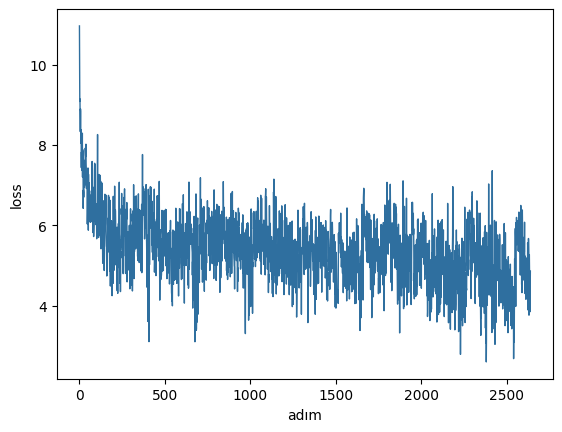

In [9]:
# metnin tamamında bir tur. hız ayarı yok, görev 2'de hızlandıracağız
torch.manual_seed(1337)
if device == "cuda":
    torch.cuda.manual_seed(1337)

train_loader = DataLoaderLite(B=4, T=32)
model = GPT(GPTConfig()).to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4)

n_adim = len(train_loader.tokens) // (4 * 32)
losses = []
t0 = time.time()
for i in range(n_adim):
    x, y = train_loader.next_batch()
    x, y = x.to(device), y.to(device)
    optimizer.zero_grad()
    logits, loss = model(x, y)
    loss.backward()
    optimizer.step()
    losses.append(loss.item())
    if i % 300 == 0 or i == n_adim - 1:
        print(f"step {i:4d}, loss: {loss.item():.4f}")
print(f"toplam süre: {time.time() - t0:.0f} sn")

plt.plot(losses, color="#2f6f9f", linewidth=1)
plt.xlabel("adım"); plt.ylabel("loss")

### Metnin tamamında bir tur

Gördüğünüz gibi loss bir turda (2.640 adım, 204 saniye) **10,96'dan 4,87'ye** indi. İlk birkaç yüz adımda hızlı düşüyor, sonra yavaşlıyor.

Eğri çok gürültülü çünkü her adımda metnin farklı bir yerinden yalnızca 128 token görüyoruz. Bazı parçalar kolay, bazıları zor. Tek tek `step` satırlarına bakmak yanıltıcı (2.100. adım 5,71, 1.800. adım 7,07), asıl önemli olan eğrinin genel yönü.

Hafta 10'da loss 0,0008'e kadar inmişti, çünkü aynı batch'i ezberliyordu. Burada her adımda yeni veri var, ezberlenecek tek bir şey yok, o yüzden loss 5 civarında geziyor. Metnin tamamında öğrenmek bu demek.

# **2- Eğitimi hızlandır. Bir eğitim adımının süresini ve saniyede işlenen token sayısını ölç. Sonra videodaki adımları sırayla ekle: TF32, bfloat16 (ya da float16), torch.compile, flash attention, vocab'ı 50.304'e yuvarlamak. Her adımdan sonra süreyi tabloya yaz. Donanımın bir adımı desteklemiyorsa o adımı atla ve nedenini yaz, en az iki adımı ölçmen yeterli. Senin donanımında hangi adım en çok kazandırdı? (1:22:18 - 2:14:55)**

**Nasıl ölçüyoruz:** `adim_olc` her seferinde aynı seed ile yeni bir model kuruyor ve aynı batch'lerden 30 adım eğitiyor. İlk 5 adımı atıp kalanların medyanını alıyor, çünkü ilk adımlar bellek ayırma ve derlemeyle yavaş geçiyor.

`torch.cuda.synchronize()` şart. CPU işi GPU'ya verip beklemeden devam ediyor. Bu satır olmazsa saat GPU işini bitirmeden durur ve süre olduğundan kısa çıkar.

**Videodan tek farkımız:** Karpathy bfloat16 kullanıyor, T4'te bu yok. bfloat16'nın sayı aralığı float32 kadar geniş, float16'nınki değil: 6 × 10⁻⁸'den küçük sayılar 0'a yuvarlanıyor ve küçük gradient'ler kayboluyor. `GradScaler` loss'u büyük bir sayıyla çarpıp gradient'leri bu aralığın içinde tutuyor, optimizer adımından önce de geri bölüyor. Bu yüzden `loss.backward()` yerine `scaler.scale(loss).backward()` yazıyoruz. Ağırlıklar float32 kalıyor, float16'ya yalnızca `autocast`'in içindeki hesaplar geçiyor.

In [10]:
assert device == "cuda", "bu görevi GPU'da çalıştır"

# görev 1'in modeli hâlâ GPU'da duruyor, boşaltmazsak ölçümlerin belleğini yer
del model, optimizer, logits, loss, x, y
gc.collect(); torch.cuda.empty_cache()

# T4 Turing mimarisi, TF32 ve bfloat16 Ampere (8.0) ile geldi
surum = torch.cuda.get_device_capability()
ampere_var = surum[0] >= 8
print("GPU compute capability:", surum, " TF32 ve bfloat16 var mı:", ampere_var)

def adim_olc(ad, config, dtype=None, derle=False, n_adim=30, atla=5):
    gc.collect(); torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
    torch.manual_seed(1337); torch.cuda.manual_seed(1337)
    olcum_loader.current_position = 0 # her ölçüm aynı batch'leri görsün

    model = GPT(config).to(device)
    if derle:
        model = torch.compile(model)
    optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4)
    # float16 çok küçük gradient'leri 0'a yuvarlıyor. GradScaler loss'u büyütüp bunu engelliyor. bfloat16'da gerek yok
    scaler = torch.amp.GradScaler("cuda", enabled=dtype == torch.float16)

    sureler = []
    for i in range(n_adim):
        t0 = time.time()
        x, y = olcum_loader.next_batch()
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        with torch.autocast(device_type="cuda", dtype=dtype, enabled=dtype is not None):
            logits, loss = model(x, y)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        torch.cuda.synchronize() # wait for the GPU to finish work. yoksa süre GPU işi bitmeden ölçülür
        sureler.append(time.time() - t0)

    # ilk adımlar bellek ayırma ve derleme yüzünden yavaş, onları sayma
    orta = sorted(sureler[atla:])
    dt = orta[len(orta) // 2] # medyan
    sonuc = dict(ad=ad, dt=dt, tok=B * T / dt, ilk=sureler[0], bellek=torch.cuda.max_memory_allocated() / 1024**3, loss=loss.item())
    print(f"{ad:32} dt: {dt * 1000:6.0f}ms  tok/sec: {sonuc['tok']:8.0f}  ilk adım: {sureler[0]:5.1f}s  bellek: {sonuc['bellek']:4.1f} GB  loss: {sonuc['loss']:.3f}")
    del model, optimizer, scaler
    return sonuc

GPU compute capability: (7, 5)  TF32 ve bfloat16 var mı: False


In [11]:
# Karpathy 16 x 1024 kullanıyor. T4'e hangi batch sığıyor, deneyelim. en kötü durum bu: float32, flash yok
T = 1024
for B in [16, 8, 4]:
    # flash olmadan attention matrisi B x nh x T x T boyutunda ve her blokta bellekte kalıyor
    print(f"B={B}, T={T}: yalnız attention matrisleri, 12 blok: {B * 12 * T * T * 4 * 12 / 1024**3:.1f} GB")
    olcum_loader = DataLoaderLite(B, T)
    try:
        adim_olc(f"{B} x {T}, float32", GPTConfig(), n_adim=8, atla=3)
        break # sığdı, ölçümleri ve eğitimi bu boyutla yapacağız
    except torch.cuda.OutOfMemoryError:
        print(f"{B} x {T}: belleğe sığmadı")
print(f"ölçüm boyutu: B={B}, T={T}")

B=16, T=1024: yalnız attention matrisleri, 12 blok: 9.0 GB
loaded 338025 tokens
1 epoch = 20 batches
16 x 1024: belleğe sığmadı
B=8, T=1024: yalnız attention matrisleri, 12 blok: 4.5 GB
loaded 338025 tokens
1 epoch = 41 batches
8 x 1024: belleğe sığmadı
B=4, T=1024: yalnız attention matrisleri, 12 blok: 2.2 GB
loaded 338025 tokens
1 epoch = 82 batches
4 x 1024, float32                dt:   1380ms  tok/sec:     2969  ilk adım:   1.4s  bellek:  9.2 GB  loss: 7.710
ölçüm boyutu: B=4, T=1024


### T4'e hangi batch sığıyor

Compute capability (7, 5): T4 Turing mimarisi. TF32 ve bfloat16 Ampere (8.0) ile geldi, bu yüzden **ikisini de atlıyoruz.**

Karpathy'nin 16 × 1024'ü sığmadı, 8 × 1024 de sığmadı. **4 × 1024** sığdı ve 9,2 GB kullandı. Attention matrislerinin 2,2 GB'lık hesabı yalnızca bir alt sınır. Üstüne autograd'ın geri yayılım için tuttuğu ara sonuçlar, 0,77 GB'lık logits (4 × 1024 × 50.257 × 4 byte), model, gradient'ler ve Adam'ın durumu geliyor.

`T` = 1024'te kaldım, gerçek GPT-2 bağlamı bu. Ölçümleri **B = 4, T = 1024** ile yapıyoruz.

In [12]:
sonuclar = []
config = GPTConfig()

# 0) hiçbir şey yok
sonuclar.append(adim_olc("başlangıç (float32)", config))

# 1) TF32: matris çarpımları float32 yerine 19 bitle (TF32) yapılıyor
if ampere_var:
    torch.set_float32_matmul_precision("high")
    sonuclar.append(adim_olc("+ TF32", config))
else:
    print("TF32 atlandı: GPU Ampere'den eski, tensor core'larında TF32 yok")

# 2) autocast: bfloat16 varsa o, yoksa float16
dtype = torch.bfloat16 if ampere_var else torch.float16
sonuclar.append(adim_olc(f"+ autocast ({dtype})".replace("torch.", ""), config, dtype=dtype))

# 3) torch.compile
sonuclar.append(adim_olc("+ torch.compile", config, dtype=dtype, derle=True))

# 4) flash attention
config = GPTConfig(flash=True)
sonuclar.append(adim_olc("+ flash attention", config, dtype=dtype, derle=True))

# 5) vocab'ı 50.304'e yuvarlamak
config = GPTConfig(flash=True, vocab_size=50304)
sonuclar.append(adim_olc("+ vocab 50304", config, dtype=dtype, derle=True))

print()
print(f"{'adım':32}{'dt (ms)':>9}{'tok/sec':>10}{'öncekine göre':>15}{'başlangıca göre':>17}")
for i, s in enumerate(sonuclar):
    onceki = sonuclar[i - 1]["dt"] / s["dt"] if i else 1
    print(f"{s['ad']:32}{s['dt'] * 1000:>9.0f}{s['tok']:>10.0f}{onceki:>14.2f}x{sonuclar[0]['dt'] / s['dt']:>16.2f}x")
print()
print("50304 = 2^7 x", 50304 // 128, " 50257 tek sayı mı:", 50257 % 2 == 1)

başlangıç (float32)              dt:   1418ms  tok/sec:     2889  ilk adım:   1.4s  bellek:  9.2 GB  loss: 6.505
TF32 atlandı: GPU Ampere'den eski, tensor core'larında TF32 yok
+ autocast (float16)             dt:    509ms  tok/sec:     8053  ilk adım:   0.7s  bellek:  8.8 GB  loss: 6.505


W1031 17:20:22.079000 24 torch/_inductor/utils.py:1731] [0/0] Not enough SMs to use max_autotune_gemm mode


+ torch.compile                  dt:    362ms  tok/sec:    11302  ilk adım:  35.2s  bellek:  7.0 GB  loss: 6.505
+ flash attention                dt:    323ms  tok/sec:    12677  ilk adım:  20.2s  bellek:  4.7 GB  loss: 6.504
+ vocab 50304                    dt:    295ms  tok/sec:    13892  ilk adım:  19.6s  bellek:  4.4 GB  loss: 6.537

adım                              dt (ms)   tok/sec  öncekine göre  başlangıca göre
başlangıç (float32)                  1418      2889          1.00x            1.00x
+ autocast (float16)                  509      8053          2.79x            2.79x
+ torch.compile                       362     11302          1.40x            3.91x
+ flash attention                     323     12677          1.12x            4.39x
+ vocab 50304                         295     13892          1.10x            4.81x

50304 = 2^7 x 393  50257 tek sayı mı: True


### Sonuç tablosu

Adımlar birikimli, her satır üstündekilerin hepsini içeriyor. B = 4, T = 1024, yani adım başına 4.096 token.

| Adım | Adım süresi | Token / sn | Öncekine göre | Başlangıca göre | Bellek |
|---|---|---|---|---|---|
| Başlangıç (float32) | 1.418 ms | 2.889 | | 1,00× | 9,2 GB |
| TF32 | atlandı | | T4'te yok (Ampere'den eski) | | |
| bfloat16 | atlandı | | T4'te yok, yerine float16 | | |
| + float16 (autocast) | 509 ms | 8.053 | **2,79×** | 2,79× | 8,8 GB |
| + torch.compile | 362 ms | 11.302 | 1,40× | 3,91× | 7,0 GB |
| + flash attention | 323 ms | 12.677 | 1,12× | 4,39× | 4,7 GB |
| + vocab 50.304 | 295 ms | 13.892 | 1,10× | **4,81×** | 4,4 GB |

### Hangi adım en çok kazandırdı

**float16.** Tek başına 2,79 kat. T4'ün tensor core'ları matris çarpımlarını yalnız float16'da hızlandırıyor. float32'de bu donanım boşta kalıyordu, tek satır `autocast` onu devreye soktu. Karpathy'nin kartında sıralama farklı olabilir, çünkü orada TF32 float32'yi de hızlandırıyor.

### Tablodan çıkanlar

- **Ölçüm gürültüsü:** Aynı ayarı iki kez ölçtük (batch denemesinde 1.380 ms, başlangıçta 1.418 ms), %3 fark var. %10'luk kazançlar bunun üstünde ama kesin sayı gibi okumamak lazım.
- **Hızlandırmalar hesabı değiştirmiyor:** İlk üç ölçümde 30. adımın loss'u 6,505, flash ile 6,504. Son satırda 6,537 çünkü matrisin boyutu değişince rastgele başlangıç değerleri de değişiyor.
- **torch.compile bedava değil:** İlk adım 35,2 saniye sürdü (sonraki iki ölçümde 20 saniye civarı). Adım başına 147 ms kazandırdığı için kendini yaklaşık 240 adımda ödüyor. Uzun eğitimde şart, 50 adımlık denemede gereksiz.
- **Flash attention'ın asıl kazancı T4'te bellek:** Hız 1,12 kat ama bellek 7,0'dan 4,7 GB'a indi, çünkü attention matrisi artık bellekte tutulmuyor. Küçük GPU'da bu, hızdan daha değerli.
- **Vocab 50.304:** 50.257 tek sayı, 50.304 ise 2⁷ × 393. Fazladan 47 token verimizde hiç geçmiyor, model onlara düşük olasılık vermeyi öğreniyor, parametre sayısı yalnızca 36 bin artıyor. Burada 1,10 kat kazandırdı. GPU'nun neden böyle sayıları sevdiği karta bağlı, Karpathy de bunu 2'nin kuvvetleriyle çalışan donanım diye anlatıyor.

# **3- GPT-3'ün eğitim ayarlarını kur. AdamW'yi videodaki beta'larla kur, gradient clipping ekle ve her adımda gradient norm'u yazdır. Warmup'lı cosine learning rate schedule yaz ve eğrisini çiz. Weight decay'i yalnız 2 boyutlu parametrelere uygula, kaç parametreye uygulandığını yaz. Sonra gradient accumulation ekle: küçük batch'lerle büyük bir batch'in gradient'ini topla. Loss'u neden accumulation adım sayısına böldüğümüzü kendi cümlelerinle yaz. (2:14:55 - 2:46:52)**

GPT-3 makalesinin ek B'si eğitim ayarlarını birkaç cümlede veriyor. Bizim ölçeğimize çevirince şöyle oluyor:

| Ayar | GPT-3 ek B | Bizde |
|---|---|---|
| Adam | β1 = 0,9, β2 = 0,95, ε = 10⁻⁸ | aynı |
| Gradient clipping | global norm 1,0 | aynı |
| Weight decay | 0,1 | aynı |
| lr düşüşü | cosine, lr'nin %10'una kadar, 260 milyar token | 6e-4'ten 6e-5'e, 300 adım |
| Warmup | ilk 375 milyon token, doğrusal | ilk 30 adım (yaklaşık 1 milyon token) |
| Batch | 32 bin token'dan başlayıp büyüyor | sabit 32.768 token |

Ek B lr'nin kendisini yazmıyor, 6e-4 Karpathy'nin değeri.

Önce weight decay. Parametreleri iki gruba ayırıyoruz: 2 boyutlu olanlara decay uygulanıyor, 1 boyutlulara uygulanmıyor. `fused=True` da AdamW'nin CUDA'da daha hızlı çalışan sürümü.

In [13]:
def configure_optimizers(model, weight_decay, learning_rate):
    # start with all of the candidate parameters (that require grad)
    param_dict = {pn: p for pn, p in model.named_parameters()}
    param_dict = {pn: p for pn, p in param_dict.items() if p.requires_grad}
    # create optim groups. Any parameters that is 2D will be weight decayed, otherwise no.
    # i.e. all weight tensors in matmuls + embeddings decay, all biases and layernorms don't.
    decay_params = [p for n, p in param_dict.items() if p.dim() >= 2]
    nodecay_params = [p for n, p in param_dict.items() if p.dim() < 2]
    optim_groups = [
        {"params": decay_params, "weight_decay": weight_decay},
        {"params": nodecay_params, "weight_decay": 0.0}
    ]
    num_decay_params = sum(p.numel() for p in decay_params)
    num_nodecay_params = sum(p.numel() for p in nodecay_params)
    print(f"num decayed parameter tensors: {len(decay_params)}, with {num_decay_params:,} parameters")
    print(f"num non-decayed parameter tensors: {len(nodecay_params)}, with {num_nodecay_params:,} parameters")
    # Create AdamW optimizer and use the fused version if it is available
    fused_available = "fused" in inspect.signature(torch.optim.AdamW).parameters
    use_fused = fused_available and device == "cuda"
    print(f"using fused AdamW: {use_fused}")
    optimizer = torch.optim.AdamW(optim_groups, lr=learning_rate, betas=(0.9, 0.95), eps=1e-8, fused=use_fused) # beta'lar ve eps GPT-3 ek B'den
    return optimizer

model = GPT(GPTConfig(vocab_size=50304, flash=True)).to(device)
optimizer = configure_optimizers(model, weight_decay=0.1, learning_rate=6e-4)

# hangi tensorlar hangi grupta
for ad, p in model.named_parameters():
    if "h.0." in ad or "h." not in ad:
        print(f"{'decay' if p.dim() >= 2 else 'yok':6}{ad:42}{str(tuple(p.shape)):>16}")
del model, optimizer # burada yalnızca sayıları görmek istedik

num decayed parameter tensors: 50, with 124,354,560 parameters
num non-decayed parameter tensors: 98, with 121,344 parameters
using fused AdamW: True
decay transformer.wte.weight                        (50304, 768)
decay transformer.wpe.weight                         (1024, 768)
yok   transformer.h.0.ln_1.weight                         (768,)
yok   transformer.h.0.ln_1.bias                           (768,)
decay transformer.h.0.attn.c_attn.weight             (2304, 768)
yok   transformer.h.0.attn.c_attn.bias                   (2304,)
decay transformer.h.0.attn.c_proj.weight              (768, 768)
yok   transformer.h.0.attn.c_proj.bias                    (768,)
yok   transformer.h.0.ln_2.weight                         (768,)
yok   transformer.h.0.ln_2.bias                           (768,)
decay transformer.h.0.mlp.c_fc.weight                (3072, 768)
yok   transformer.h.0.mlp.c_fc.bias                      (3072,)
decay transformer.h.0.mlp.c_proj.weight              (768, 3072)
yok  

### Weight decay kaç parametreye uygulandı

**124.354.560 parametreye** (50 tensor), yani modelin %99,9'una. Uygulanmayan 121.344 parametre (98 tensor). Toplam 124.475.904, vocab 50.304 olduğu için 124.439.808'den 36.096 fazla.

- **2 boyutlu olanlar:** Matris çarpımlarının ağırlıkları ve embedding'ler. Bir bloktan 4 ağırlık, 12 blokta 48 tensor, üstüne `wte` ve `wpe`: 50. `lm_head`, `wte` ile aynı tensor olduğu için 51 değil.
- **1 boyutlu olanlar:** Linear bias'ları ve LayerNorm'ların weight ve bias'ı. Blok başına 8 tensor, 12 blokta 96, üstüne `ln_f`'in 2'si: 98.

Weight decay büyük ağırlıkları küçülmeye zorluyor, model tek tük bağlantılara dayanmak yerine ağırlığı yayıyor. Bias ve LayerNorm parametreleri ise yalnızca kaydırma ve ölçek ayarı yapıyor, onları sıfıra çekmek bir şey kazandırmıyor, modeli bozabiliyor.

Şimdi learning rate schedule. Üç parça var: warmup'ta doğrusal yükseliyor, sonra cosine ile iniyor, `max_steps`'ten sonra `min_lr`'de kalıyor. `warmup_steps` ve `max_steps`'i uzun eğitimin küçültülmüş hali olarak seçtim, adımların %10'u warmup.

adım 0: 2.00e-05  adım 30: 6.00e-04  adım 165: 3.30e-04  adım 300: 6.00e-05


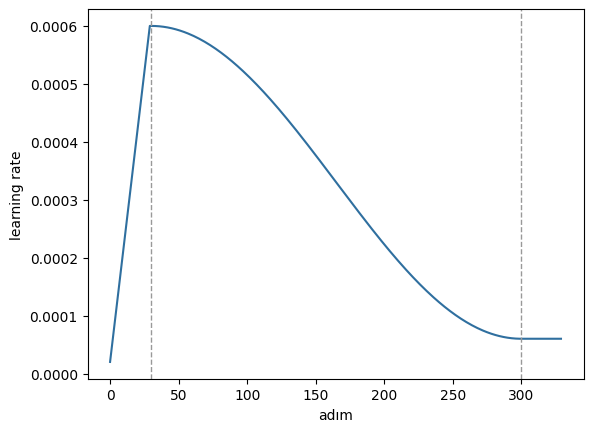

In [14]:
max_lr = 6e-4
min_lr = max_lr * 0.1 # GPT-3: lr'nin %10'una kadar iniyor
warmup_steps = 30
max_steps = 300 # makalede 260 milyar token, bizde birkaç yüz adım

def get_lr(it):
    # 1) linear warmup for warmup_iters steps
    if it < warmup_steps:
        return max_lr * (it + 1) / warmup_steps
    # 2) if it > lr_decay_iters, return min learning rate
    if it > max_steps:
        return min_lr
    # 3) in between, use cosine decay down to min learning rate
    decay_ratio = (it - warmup_steps) / (max_steps - warmup_steps)
    assert 0 <= decay_ratio <= 1
    coeff = 0.5 * (1.0 + math.cos(math.pi * decay_ratio)) # coeff starts at 1 and goes to 0
    return min_lr + coeff * (max_lr - min_lr)

# uç noktaları kontrol
assert math.isclose(get_lr(0), max_lr / warmup_steps) # 0 değil, ilk adım da bir şey öğrensin
assert math.isclose(get_lr(warmup_steps - 1), max_lr)
assert math.isclose(get_lr(warmup_steps), max_lr)
assert math.isclose(get_lr(max_steps), min_lr)
assert get_lr(max_steps + 100) == min_lr

plt.plot([get_lr(i) for i in range(max_steps + 30)], color="#2f6f9f")
plt.axvline(warmup_steps, color="#999999", linestyle="--", linewidth=1)
plt.axvline(max_steps, color="#999999", linestyle="--", linewidth=1)
plt.xlabel("adım"); plt.ylabel("learning rate")
print(f"adım 0: {get_lr(0):.2e}  adım {warmup_steps}: {get_lr(warmup_steps):.2e}  adım {max_steps // 2 + warmup_steps // 2}: {get_lr(max_steps // 2 + warmup_steps // 2):.2e}  adım {max_steps}: {get_lr(max_steps):.2e}")

Uç noktaları `assert`'lerle kontrol ettik: ilk adımda 2e-5 (0 değil, yoksa ilk adım boşa gider), 30. adımda tepe 6e-4, 300. adımda 6e-5 ve sonrasında sabit.

**Neden warmup:** Model başta rastgele, gradient'ler büyük ve yönleri güvenilmez. Birazdan göreceğiz, ilk adımda gradient norm 29,9. Tam lr ile başlarsak o ilk adımlar modeli sağa sola savurur.

**Neden sonda düşüyor:** Minimuma yaklaştıkça büyük adımlar etrafında dolaşmaya sebep oluyor. lr'yi kısınca model daha ince ayar yapabiliyor.

Son parça gradient accumulation. T4'te bir kerede 4 × 1024 sığıyor ama Karpathy'nin hedefi 32.768 token'lık batch. Çözüm: küçük batch'leri sırayla geçirmek, `backward()` ile gradient'leri biriktirmek ve optimizer adımını ancak sonunda atmak.

Bunu tam eğitime koymadan önce gerçekten aynı gradient'i verdiğini ölçelim. 8'lik bir batch'in gradient'ini 2'şerlik 4 batch'ten topluyoruz.

In [15]:
# gradient accumulation gerçekten büyük batch'in gradient'ini veriyor mu?
def grad_vektor(model):
    return torch.cat([p.grad.view(-1) for p in model.parameters()]).clone()

torch.manual_seed(1337)
model = GPT(GPTConfig(flash=True)).to(device) # float32, autocast yok: yuvarlama farkı karışmasın
x = train_loader.tokens[:8 * 64].view(8, 64).to(device)
y = train_loader.tokens[1:8 * 64 + 1].view(8, 64).to(device)

# 1) tek büyük batch: B = 8
model.zero_grad()
_, loss = model(x, y)
loss.backward()
g_buyuk = grad_vektor(model)

# 2) 4 küçük batch: B = 2, loss / 4
model.zero_grad()
for xk, yk in zip(x.chunk(4), y.chunk(4)):
    _, loss = model(xk, yk)
    (loss / 4).backward()
g_bolunmus = grad_vektor(model)

# 3) 4 küçük batch: bölmeden
model.zero_grad()
for xk, yk in zip(x.chunk(4), y.chunk(4)):
    _, loss = model(xk, yk)
    loss.backward()
g_bolunmemis = grad_vektor(model)

print(f"büyük batch norm:        {g_buyuk.norm().item():.4f}")
print(f"loss / 4 ile norm:       {g_bolunmus.norm().item():.4f}   göreli fark: {(g_bolunmus - g_buyuk).norm().item() / g_buyuk.norm().item():.2e}")
print(f"bölmeden norm:           {g_bolunmemis.norm().item():.4f}   büyük batch'e oranı: {g_bolunmemis.norm().item() / g_buyuk.norm().item():.2f}")
del model, g_buyuk, g_bolunmus, g_bolunmemis; gc.collect(); torch.cuda.empty_cache()

büyük batch norm:        33.3858
loss / 4 ile norm:       33.3858   göreli fark: 6.58e-07
bölmeden norm:           133.5430   büyük batch'e oranı: 4.00


### Loss'u neden accumulation adım sayısına bölüyoruz

| | Gradient norm |
|---|---|
| Tek büyük batch (B = 8) | 33,3858 |
| 4 küçük batch, `loss / 4` | 33,3858 (göreli fark 6,6 × 10⁻⁷) |
| 4 küçük batch, bölmeden | 133,5430 (tam 4,00 kat) |

**Kendi cümlelerimle:** `F.cross_entropy` batch'teki token'ların ortalamasını alıyor. `backward()` ise yeni gradient'i `.grad`'ın üstüne ekliyor. Bölmezsek dört ayrı ortalamanın gradient'ini **toplamış** oluyoruz, sonuç büyük batch'in gradient'inin 4 katı. Oysa büyük batch'te hepsinin tek bir ortalaması alınıyordu. Her loss'u 4'e bölünce toplam yine ortalamaya dönüyor. Bunun tutması için küçük batch'lerin eşit boyda olması gerekiyor, burada eşit.

Fark tam 0 değil, çünkü aynı sayılar farklı sırayla toplanınca float32'de son basamaklar değişiyor (hafta 10'daki logits farkının aynısı).

Şimdi her şeyi birleştirip eğitelim. Burada float16 yüzünden videodan bir satır farklıyız: `scaler.unscale_(optimizer)`. Gradient'ler `GradScaler`'ın çarpanıyla büyümüş halde bekliyor, clipping'den önce gerçek değerlerine dönmeleri gerekiyor. Yoksa norm'u yanlış sayıya göre keseriz.

In [16]:
total_batch_size = 32768 # Karpathy'nin hedefi: 2^15 token
grad_accum_steps = total_batch_size // (B * T)
print(f"total desired batch size: {total_batch_size}")
print(f"=> calculated gradient accumulation steps: {grad_accum_steps}")

torch.manual_seed(1337); torch.cuda.manual_seed(1337)
train_loader = DataLoaderLite(B, T)

if ampere_var:
    torch.set_float32_matmul_precision("high")
model = GPT(GPTConfig(vocab_size=50304, flash=True)).to(device)
model = torch.compile(model)
optimizer = configure_optimizers(model, weight_decay=0.1, learning_rate=max_lr)
scaler = torch.amp.GradScaler("cuda", enabled=dtype == torch.float16) # bfloat16'da hiçbir şey yapmıyor

kayit = dict(loss=[], lr=[], norm=[], dt=[])
for step in range(max_steps):
    t0 = time.time()
    optimizer.zero_grad()
    loss_accum = 0.0
    for micro_step in range(grad_accum_steps):
        x, y = train_loader.next_batch()
        x, y = x.to(device), y.to(device)
        with torch.autocast(device_type="cuda", dtype=dtype):
            logits, loss = model(x, y)
        # we have to scale the loss to account for gradient accumulation,
        # because the gradients just add on each successive backward().
        # addition of gradients corresponds to a SUM in the objective, but
        # instead of a SUM we want MEAN. Scale the loss here so it comes out right
        loss = loss / grad_accum_steps
        loss_accum += loss.detach()
        scaler.scale(loss).backward()
    scaler.unscale_(optimizer) # float16: gradient'ler hâlâ scaler'ın çarpanıyla büyük. clip'ten önce gerçek değerine dönmeli
    norm = torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    # determine and set the learning rate for this iteration
    lr = get_lr(step)
    for param_group in optimizer.param_groups:
        param_group["lr"] = lr
    scaler.step(optimizer)
    scaler.update()
    torch.cuda.synchronize() # wait for the GPU to finish work
    dt = time.time() - t0
    tokens_per_sec = B * T * grad_accum_steps / dt
    kayit["loss"].append(loss_accum.item()); kayit["lr"].append(lr); kayit["norm"].append(norm.item()); kayit["dt"].append(dt)
    print(f"step {step:4d} | loss: {loss_accum.item():.6f} | lr {lr:.4e} | norm: {norm.item():.4f} | dt: {dt * 1000:.0f}ms | tok/sec: {tokens_per_sec:.0f}")

total desired batch size: 32768
=> calculated gradient accumulation steps: 8
loaded 338025 tokens
1 epoch = 82 batches
num decayed parameter tensors: 50, with 124,354,560 parameters
num non-decayed parameter tensors: 98, with 121,344 parameters
using fused AdamW: True
step    0 | loss: 10.940182 | lr 2.0000e-05 | norm: 29.8834 | dt: 2313ms | tok/sec: 14167
step    1 | loss: 9.875296 | lr 4.0000e-05 | norm: 13.1443 | dt: 2208ms | tok/sec: 14842
step    2 | loss: 9.405432 | lr 6.0000e-05 | norm: 11.1802 | dt: 2224ms | tok/sec: 14732
step    3 | loss: 9.620179 | lr 8.0000e-05 | norm: 9.5040 | dt: 2222ms | tok/sec: 14749
step    4 | loss: 9.145282 | lr 1.0000e-04 | norm: 5.0013 | dt: 2219ms | tok/sec: 14769
step    5 | loss: 8.970503 | lr 1.2000e-04 | norm: 3.2107 | dt: 2208ms | tok/sec: 14843
step    6 | loss: 8.816051 | lr 1.4000e-04 | norm: 2.4240 | dt: 2208ms | tok/sec: 14840
step    7 | loss: 8.717970 | lr 1.6000e-04 | norm: 2.7693 | dt: 2188ms | tok/sec: 14977
step    8 | loss: 8.553

loss: ilk 10.940, adım 30: 6.009, adım 150: 4.905, son 3.964
norm: ilk 29.88, en büyük 29.88, son 1.32
clip'e takılan adım: 227 / 300, sonsuz norm (atlanan adım): 0
medyan adım süresi: 2.05 s, tok/sec: 15987, toplam token: 9,830,400 (29.1 epoch)


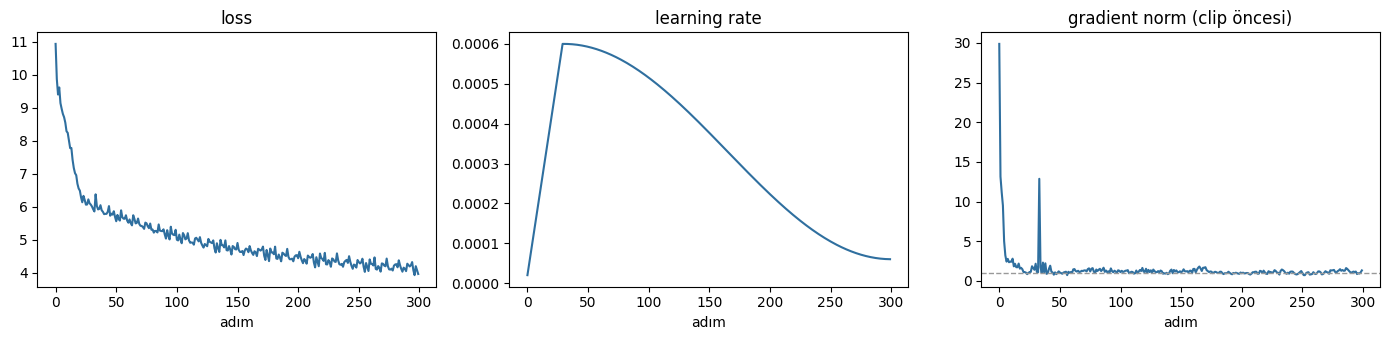

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
axes[0].plot(kayit["loss"], color="#2f6f9f"); axes[0].set_title("loss"); axes[0].set_xlabel("adım")
axes[1].plot(kayit["lr"], color="#2f6f9f"); axes[1].set_title("learning rate"); axes[1].set_xlabel("adım")
axes[2].plot(kayit["norm"], color="#2f6f9f"); axes[2].axhline(1.0, color="#999999", linestyle="--", linewidth=1)
axes[2].set_title("gradient norm (clip öncesi)"); axes[2].set_xlabel("adım")
plt.tight_layout()

finite = [n for n in kayit["norm"] if math.isfinite(n)]
print(f"loss: ilk {kayit['loss'][0]:.3f}, adım {warmup_steps}: {kayit['loss'][warmup_steps]:.3f}, adım {max_steps // 2}: {kayit['loss'][max_steps // 2]:.3f}, son {kayit['loss'][-1]:.3f}")
print(f"norm: ilk {kayit['norm'][0]:.2f}, en büyük {max(finite):.2f}, son {kayit['norm'][-1]:.2f}")
print(f"clip'e takılan adım: {sum(n > 1.0 for n in kayit['norm'])} / {len(kayit['norm'])}, sonsuz norm (atlanan adım): {len(kayit['norm']) - len(finite)}")
orta = sorted(kayit["dt"][5:])[len(kayit["dt"][5:]) // 2]
print(f"medyan adım süresi: {orta:.2f} s, tok/sec: {total_batch_size / orta:.0f}, toplam token: {max_steps * total_batch_size:,} ({max_steps * total_batch_size / len(train_loader.tokens):.1f} epoch)")

### Eğitimin sonucu

- **Accumulation:** 32.768 / (4 × 1024) = 8 küçük batch. T4'e sığmayan büyük batch'in gradient'ini bu şekilde topladık.
- **Hız:** Adım başına 2,05 saniye, **15.987 token / sn.** Görev 2'nin 13.892'sinden yüksek çünkü fused AdamW kullanıyoruz ve optimizer adımı her küçük batch'te değil 8 küçük batch'te bir atılıyor. İkisini ayrı ayrı ölçmedim.
- **Loss:** 10,94 → warmup sonunda 6,01 → 150. adımda 4,91 → son **3,96**. Birinci görevdeki eğriye göre çok daha pürüzsüz, çünkü her adım 128 değil 32.768 token'ın ortalaması.
- **Gradient norm:** İlk adımda 29,9, warmup bitmeden 1 civarına iniyor. Clipping uygulanmasaydı ilk adımlar çok büyük olurdu, warmup ile birlikte bu adımlar zararsızlaşıyor. Eşik 1,0 olduğu için 300 adımın 227'si kesildi, yani sonraki adımlar da sık sık sınıra değiyor.
- **33. adımdaki sıçrama:** Norm bir anda 12,9'a çıktı, loss 5,86'dan 6,38'e sıçradı, 2 adımda toparlandı. lr'nin tepeye ulaştığı yerin hemen sonrası. Clipping bu gradient'i optimizer'a girmeden önce norm 1,0'a indirdi.
- **float16:** Sonsuz norm yok, `GradScaler` hiç adım atlamadı.

Toplamda 9,8 milyon token gördük, bu metnin 29 katı (29 epoch).

In [18]:
# modeli konuşturalım. torch.compile'ın içindeki asıl model _orig_mod
def sample(model, prompt, num_return_sequences=3, max_length=60, seed=42):
    tokens = enc.encode(prompt)
    tokens = torch.tensor(tokens, dtype=torch.long)
    x = tokens.unsqueeze(0).repeat(num_return_sequences, 1).to(device)
    torch.manual_seed(seed); torch.cuda.manual_seed(seed)
    while x.size(1) < max_length:
        with torch.no_grad():
            logits, _ = model(x)
            probs = F.softmax(logits[:, -1, :], dim=-1)
            topk_probs, topk_indices = torch.topk(probs, 50, dim=-1)
            ix = torch.multinomial(topk_probs, 1)
            x = torch.cat((x, torch.gather(topk_indices, -1, ix)), dim=1)
    for i in range(num_return_sequences):
        print(">", enc.decode(x[i].tolist()))
        print()

m = model._orig_mod
m.eval()
sample(m, "First Citizen:\n")
sample(m, "KING HENRY:\nWhat news from")

> First Citizen:
I do be not be theUS:
That you here's one a good, but but a word to the duke.

CALUS:
MENENIUS:
HORELCES:
My wife, I not,
Nay,

> First Citizen:
PETARD III:

You pray,
KOP OVERA people
IUS:
NIA:
IUS:
Dost't.


For this is there hath; but 'twas, and your life's name, I know; and

> First Citizen:

I did not live on these we have heard's
To give him.
IET:
I have gone, I am it.
IOLANLEY:
I'll know he is well so.
Let her.

Then

SICIN

> KING HENRY:
What news from the king and do, that will go your state?
And make myself:
The most gracious heart?
That my lord.
By the head of that ever

What news to yourself
My lord, my body with a good lord

> KING HENRY:
What news from my head.


LUCENTIO:
IUS:

And let us in your mistress:


I had, will say it.

So I
Thou did never to be the house of me and he

> KING HENRY:
What news from my lord I do call
PTHUMUS:
You do you, we will be not give me.



CORIUS:






CORIUS:

AUTOLANUS:





Çıktı artık Shakespeare'in biçimine benziyor: büyük harfli rol adları, iki nokta, satır aralarında `lord`, `thou`, `gracious`, `my wife`. Ama anlam yok. Rol adlarının çoğu da uydurma (`CALUS`, `HORELCES`, `KOP OVERA`).

Rastgele başlatılmış bir modelin birbirini tutmayan token'lar dizeceğini düşününce fark büyük, ama bu yalnızca eğitim verisindeki loss. Val seti ayırmadık, yani 3,96'nın ne kadarının gerçekten öğrenme, ne kadarının ezber olduğunu bilmiyoruz. Bu gelecek haftanın işi.

## Özet

- Data loader metni ardışık batch'lerle geziyor. Bir tur (2.640 adım, 128 token'lık batch) loss'u 10,96'dan 4,87'ye indirdi.
- Weight tying 38.597.376 parametre kazandırdı (%23,7): 163M'den 124M'e.
- Residual katmanları 1/√(2·n_layer) ile ölçeklemek son std'yi blok sayısından bağımsız yapıyor. Modelde ölçeksiz/ölçekli oranı 4,97, √24 = 4,90.
- T4'te TF32 ve bfloat16 yok, yerine float16 + `GradScaler` kullandık. Karpathy'nin 16 × 1024'ü flash'sız float32'de sığmadı, 4 × 1024 ile ölçtük.
- Adım süresi 1.418 ms'den 295 ms'ye indi: **4,81 kat**, 2.889'dan 13.892 token / sn'ye. En çok kazandıran float16 (2,79×). Flash attention'ın asıl katkısı bellek oldu (7,0'dan 4,7 GB'a).
- GPT-3 ayarları: AdamW (0,9 / 0,95 / 1e-8), clipping 1,0, weight decay 0,1, warmup + cosine. Weight decay 124.354.560 parametreye uygulandı, 121.344'e uygulanmadı.
- Gradient accumulation büyük batch'in gradient'ini 6,6 × 10⁻⁷ göreli farkla verdi. Loss'u bölmeyince norm tam 4 kat çıkıyor.
- 300 adımda (8 × 4 × 1024 = 32.768 token'lık adım) loss 3,96'ya indi. Val seti olmadığı için bunun ne kadar genelleştiğini bilmiyoruz, onu gelecek hafta ölçeceğiz.